# Análises Práticas e Interpretação

Estudos de caso com perguntas, soluções e leitura crítica dos resultados.

Os exemplos usam arquivos pequenos da pasta `datasets/` e podem ser executados na ordem. Exercícios resolvidos aparecem junto dos respectivos enunciados.

**Objetivo:** estruturar uma análise de ponta a ponta: pergunta → auditoria → cálculo → visualização → conclusão limitada pela qualidade dos dados.

### Materiais complementares

- [Guia — Estudos práticos](./reference_materials/06_analises_praticas_e_interpretacao.pdf)
- [Cheat sheet — EDA](./cheat_sheets/cheat_sheet_eda.pdf)
- [Cheat sheet — Agrupamentos](./cheat_sheets/cheat_sheet_agrupamentos.pdf)

Os arquivos estão nesta mesma pasta da disciplina. Os PDFs complementam, mas não substituem, a execução das células.

## Estudo 1 — Vendas sintéticas: da pergunta à conclusão

**Questão:** quais produtos concentram maior volume de unidades e a receita acompanha o mesmo padrão? As respostas se referem somente ao dataset artificial incluído.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def preparar_pastas():
    """Localiza a biblioteca e cria as pastas de dados e resultados, se ausentes."""
    atual = Path.cwd().resolve()
    # Aceita execução na raiz da biblioteca ou em uma pasta filha.
    candidatos = [atual, atual.parent]
    raiz = next(
        (p for p in candidatos if (p / 'vendas_exemplo.csv').is_file() or
         (p / 'datasets' / 'vendas_exemplo.csv').is_file()),
        None,
    )
    if raiz is None:
        # Identifica a raiz da biblioteca pelo conjunto de notebooks.
        raiz = next(
            (p for p in candidatos if (p / '01_Analise_Exploratoria_de_Dados.ipynb').is_file()),
            atual,
        )
    dados = raiz / 'datasets'
    saidas = raiz / 'outputs'
    dados.mkdir(parents=True, exist_ok=True)
    saidas.mkdir(parents=True, exist_ok=True)
    return dados, saidas

DATA, OUTPUTS = preparar_pastas()

def conferir_datasets(*nomes):
    ausentes = [nome for nome in nomes if not (DATA / nome).is_file()]
    if ausentes:
        raise FileNotFoundError(
            'Datasets ausentes: ' + ', '.join(ausentes) + '\n'
            + 'Coloque os CSVs fornecidos em: ' + str(DATA.resolve()) + '\n'
            + 'Criar a pasta datasets/ não cria automaticamente os arquivos CSV.'
        )
conferir_datasets('vendas_exemplo.csv', 'reclamacoes_sinteticas.csv', 'clima_sintetico.csv')
import matplotlib.pyplot as plt
vendas=pd.read_csv(DATA/'vendas_exemplo.csv').drop_duplicates()
vendas['receita']=vendas['unidades']*vendas['preco_unitario']
produto=vendas.groupby('produto').agg(unidades=('unidades','sum'),receita=('receita', lambda s: s.sum(min_count=1))).sort_values('receita',ascending=False)
print(produto.round(2))

         unidades  receita
produto                   
Chá           551   7714.0
Café          412   7416.0
Suco          644   7188.0
Água          768   5376.0


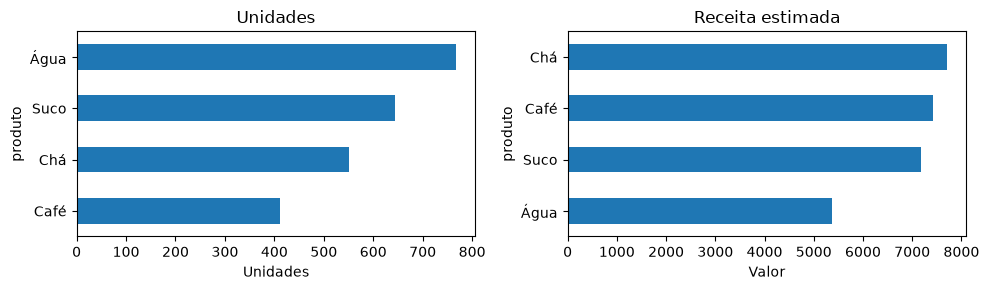

In [2]:
fig,axes=plt.subplots(1,2,figsize=(10,3))
produto['unidades'].sort_values().plot.barh(ax=axes[0],title='Unidades')
produto['receita'].sort_values().plot.barh(ax=axes[1],title='Receita estimada')
axes[0].set_xlabel('Unidades');axes[1].set_xlabel('Valor')
plt.tight_layout();plt.show()

**Interpretação:** maior quantidade não implica maior receita quando os preços diferem. Como alguns preços estão ausentes, a receita conhecida é incompleta; reporte essa limitação antes de comparar produtos.

## Estudo 2 — Reclamações: volume e desempenho

**Questão:** qual categoria tem mais reclamações e qual possui menor taxa de resolução? Evite confundir volume com qualidade de atendimento.

In [3]:
rec=pd.read_csv(DATA/'reclamacoes_sinteticas.csv')
indicadores=rec.groupby('categoria').agg(qtd=('id','size'),taxa_resolucao=('resolvida','mean'),prazo_medio=('tempo_resposta_dias','mean'))
print(indicadores.round(2).to_string())
print('Maior volume:',indicadores['qtd'].idxmax())
print('Menor taxa de resolução:',indicadores['taxa_resolucao'].idxmin())

              qtd  taxa_resolucao  prazo_medio
categoria                                     
Atendimento    41            0.68         7.61
Cancelamento   32            0.84         8.25
Cobrança       46            0.72         7.43
Entrega        41            0.71         7.56
Maior volume: Cobrança
Menor taxa de resolução: Atendimento


**Interpretação:** o dataset é sintético e pode ser usado para praticar medidas. Para inferir desempenho real, seria necessário avaliar contexto, amostragem, período, volume e definição de reclamação resolvida.

## Estudo 3 — Clima: padrões e limitações

**Questão:** a temperatura variou ao longo do período? A umidade pode ser comparada diretamente com temperatura?

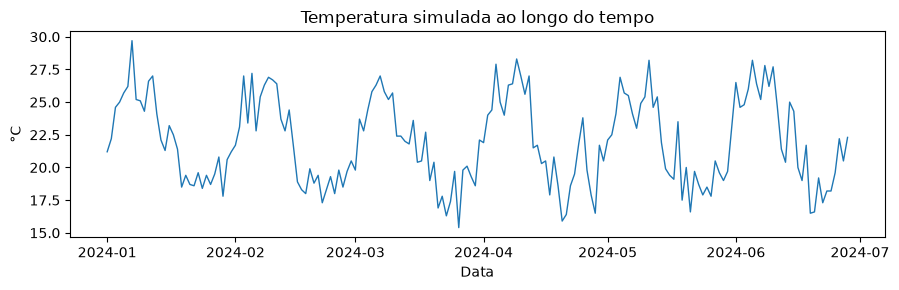

Amplitude térmica: 14.3 °C


In [4]:
clima=pd.read_csv(DATA/'clima_sintetico.csv',parse_dates=['data'])
fig,ax=plt.subplots(figsize=(9,3))
ax.plot(clima['data'],clima['temperatura_c'],linewidth=1)
ax.set(title='Temperatura simulada ao longo do tempo',xlabel='Data',ylabel='°C')
plt.tight_layout();plt.show()
print('Amplitude térmica:',round(clima.temperatura_c.max()-clima.temperatura_c.min(),1),'°C')

**Interpretação:** a visualização apresenta flutuações temporais simuladas. Não há base para inferir tendências climáticas reais nem causalidade entre variáveis, pois os dados foram gerados artificialmente.

## Exercício resolvido — síntese automatizada de qualidade

**Enunciado:** reúna número de linhas, valores ausentes e duplicações em um pequeno relatório para acompanhar as análises.

In [5]:
def resumo_qualidade(df):
    return pd.Series({'registros':len(df),'colunas':len(df.columns),'faltantes':int(df.isna().sum().sum()),'duplicacoes':int(df.duplicated().sum())})
for nome,tabela in [('vendas',vendas),('reclamacoes',rec),('clima',clima)]:
    print(nome,resumo_qualidade(tabela).to_dict())

vendas {'registros': 48, 'colunas': 7, 'faltantes': 3, 'duplicacoes': 0}
reclamacoes {'registros': 160, 'colunas': 7, 'faltantes': 0, 'duplicacoes': 0}
clima {'registros': 180, 'colunas': 4, 'faltantes': 0, 'duplicacoes': 0}


## Estudo 4 — Investigação completa de vendas
**Pergunta:** quais produtos geram mais receita e como isso muda entre canais? 
**Roteiro:** auditar dados → criar receita → agrupar → comparar proporções → visualizar → apontar limites. Os dados são sintéticos.

**Critério de qualidade:** a remoção de duplicatas neste exemplo pressupõe que registros idênticos são erro. Em dados transacionais reais, confirme uma chave única antes de aplicar essa operação. Identifique o número de preços ausentes e não converta receita desconhecida em zero.

In [6]:
base = pd.read_csv(DATA/'vendas_exemplo.csv', parse_dates=['data'])
print('Dimensões:', base.shape)
print('Ausentes por campo:', base.isna().sum().to_string())
print('Duplicados:', int(base.duplicated().sum()))
base = base.drop_duplicates().copy()
base['receita'] = base['unidades'] * base['preco_unitario']
analise = (base.groupby(['produto', 'canal'], dropna=False)
           .agg(registros=('unidades','size'), unidades=('unidades','sum'), receita=('receita', lambda s: s.sum(min_count=1))).reset_index())
print(analise.sort_values('receita', ascending=False).head(8).to_string(index=False))

Dimensões: (49, 6)
Ausentes por campo: data              0
regiao            1
produto           0
unidades          0
preco_unitario    1
canal             0
Duplicados: 1
produto  canal  registros  unidades  receita
    Chá   Loja          6       306   4284.0
   Café Online          6       237   4266.0
   Suco Online          6       329   3948.0
    Chá Online          6       245   3430.0
   Suco   Loja          6       315   3240.0
   Café   Loja          6       175   3150.0
   Água   Loja          6       413   2891.0
   Água Online          6       355   2485.0


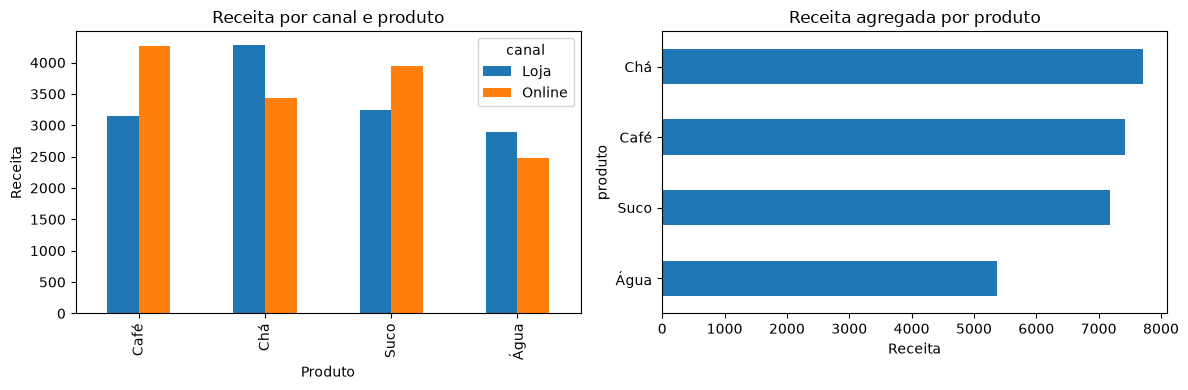

Conclusão descritiva: Chá lidera a receita neste conjunto simulado.
Limitação: não há custos, metas ou amostragem probabilística para inferências de rentabilidade.


In [7]:
grade = analise.pivot_table(index='produto', columns='canal', values='receita', aggfunc=lambda s: s.sum(min_count=1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grade.plot.bar(ax=axes[0]); axes[0].set(title='Receita por canal e produto', ylabel='Receita', xlabel='Produto')
receita_produto = grade.sum(axis=1).sort_values()
receita_produto.plot.barh(ax=axes[1]); axes[1].set(title='Receita agregada por produto', xlabel='Receita')
fig.tight_layout(); plt.show()
maior = receita_produto.idxmax()
print(f'Conclusão descritiva: {maior} lidera a receita neste conjunto simulado.')
print('Limitação: não há custos, metas ou amostragem probabilística para inferências de rentabilidade.')

## Estudo 5 — Investigação completa de reclamações
**Pergunta:** a categoria com maior volume também apresenta o maior tempo de resposta? Compare contagens, tempo médio e taxa de resolução, preservando os denominadores.

                     nulos           tipos
id                       0           int64
data                     0  datetime64[us]
regiao                   0             str
canal                    0             str
categoria                0             str
tempo_resposta_dias      0           int64
resolvida                0            bool
               n  media_dias  resolvidas  resolucao_pct
categoria                                              
Atendimento   41        7.61          28          68.29
Cancelamento  32        8.25          27          84.38
Cobrança      46        7.43          33          71.74
Entrega       41        7.56          29          70.73


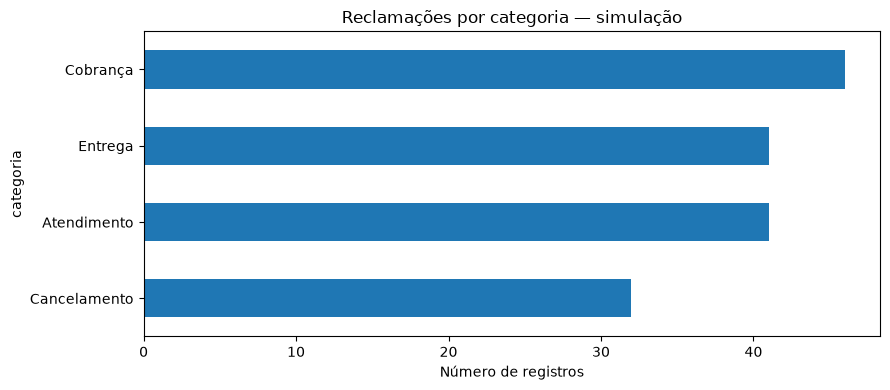

Maior volume: Cobrança | maior tempo médio: Cancelamento
Limitação: tempo médio pode ocultar caudas longas; verificar mediana e quantis.


In [8]:
rec = pd.read_csv(DATA/'reclamacoes_sinteticas.csv', parse_dates=['data'])
audit = pd.DataFrame({'nulos':rec.isna().sum(), 'tipos':rec.dtypes.astype(str)})
print(audit.to_string())
indic = (rec.groupby('categoria').agg(n=('id','size'), media_dias=('tempo_resposta_dias','mean'), resolvidas=('resolvida','sum')))
indic['resolucao_pct'] = 100 * indic['resolvidas'] / indic['n']
print(indic.round(2).to_string())
fig, ax = plt.subplots(figsize=(9, 4))
indic['n'].sort_values().plot.barh(ax=ax)
ax.set(xlabel='Número de registros', title='Reclamações por categoria — simulação')
fig.tight_layout(); plt.show()
print('Maior volume:',indic['n'].idxmax(), '| maior tempo médio:',indic['media_dias'].idxmax())
print('Limitação: tempo médio pode ocultar caudas longas; verificar mediana e quantis.')

## Estudo 6 — Investigação climática com duas métricas
**Pergunta:** os meses com maior média de temperatura coincidem com os de maior precipitação acumulada? Agregações diferentes são necessárias para variáveis com significados distintos.

            temperatura_media  chuva_acumulada
data                                          
2024-01-01              22.21             59.4
2024-02-01              21.87             45.5
2024-03-01              21.45             42.6
2024-04-01              22.05             56.8
2024-05-01              21.77             49.7
2024-06-01              22.52             35.5


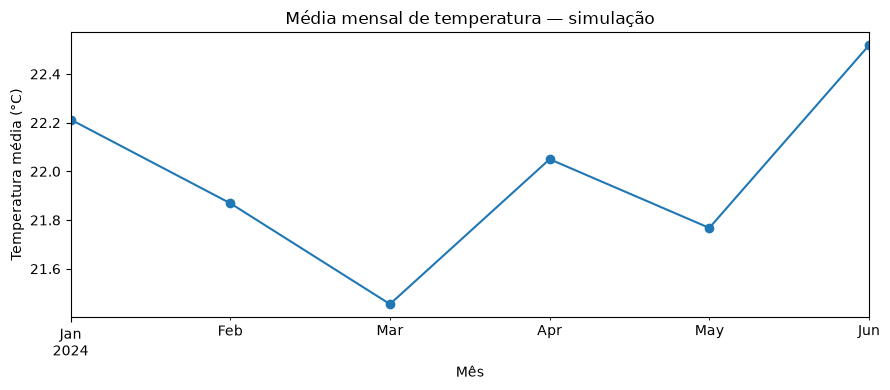

Mês mais quente: 2024-06
Mês mais chuvoso: 2024-01
Limitação: período sintético curto; não é evidência de mudança climática.


In [9]:
clim = pd.read_csv(DATA/'clima_sintetico.csv', parse_dates=['data']).sort_values('data')
mens = clim.set_index('data').resample('MS').agg(temperatura_media=('temperatura_c','mean'), chuva_acumulada=('chuva_mm','sum'))
print(mens.round(2).to_string())
fig, ax = plt.subplots(figsize=(9,4))
mens['temperatura_media'].plot(ax=ax, marker='o', ylabel='Temperatura média (°C)')
ax.set(title='Média mensal de temperatura — simulação', xlabel='Mês')
fig.tight_layout();plt.show()
print('Mês mais quente:',mens['temperatura_media'].idxmax().strftime('%Y-%m'))
print('Mês mais chuvoso:',mens['chuva_acumulada'].idxmax().strftime('%Y-%m'))
print('Limitação: período sintético curto; não é evidência de mudança climática.')

## Exercício resolvido — relatório final reprodutível
**Enunciado:** calcule número de registros, proporção de dados ausentes, receita agregada e produto líder de vendas. Escreva um resumo breve com ressalvas apropriadas.

In [10]:
def relatorio_vendas(tabela):
    t = tabela.copy()
    t['receita'] = t['unidades'] * t['preco_unitario']
    por_produto = t.groupby('produto', dropna=False)['receita'].sum(min_count=1).sort_values(ascending=False)
    return {
        'registros': len(t),
        'percentual_celulas_ausentes': round(float(t.isna().mean().mean()*100),2),
        'receita_conhecida': float(t['receita'].sum(min_count=1)),
        'registros_sem_preco': int(t['preco_unitario'].isna().sum()),
        'produto_lider_receita': por_produto.index[0]
    }
resposta = relatorio_vendas(base)
print(resposta)
assert resposta['registros'] > 0 and resposta['receita_conhecida'] >= 0
print('Interpretação: receita conhecida (incompleta com preços ausentes) da base sintética; não representa mercado real.')

{'registros': 48, 'percentual_celulas_ausentes': 0.89, 'receita_conhecida': 27694.0, 'registros_sem_preco': 1, 'produto_lider_receita': 'Chá'}
Interpretação: receita conhecida (incompleta com preços ausentes) da base sintética; não representa mercado real.


### Consulta rápida — estrutura de uma análise
1. Declare a pergunta e a unidade observacional.
2. Registre origem, período, volume e qualidade.
3. Transforme apenas o necessário; verifique o efeito das transformações.
4. Escolha gráficos que respondam à pergunta.
5. Separe **observação**, **interpretação** e **limitação**.

## Estudo 7 — Relatório integrador com cobertura e limitações

**Pergunta:** que parte dos registros de vendas contém preço válido? Como reportar a receita conhecida sem confundi-la com a receita total?

**Solução comentada:** validamos cobertura de preço e receita calculável, preservando desconhecidos como `NaN`. A conclusão deve dizer explicitamente que os resultados são sobre dados sintéticos.

In [11]:
auditoria_final = base.groupby('produto').agg(
    registros=('produto', 'size'), precos_validos=('preco_unitario', 'count'),
    unidades=('unidades', 'sum'), receita_conhecida=('receita', lambda s: s.sum(min_count=1))
)
auditoria_final['precos_ausentes'] = auditoria_final['registros'] - auditoria_final['precos_validos']
auditoria_final['cobertura_preco_pct'] = 100 * auditoria_final['precos_validos'] / auditoria_final['registros']
print(auditoria_final.round(2).to_string())
print('Conclusão: rankings de receita são parciais quando há preços ausentes; não representam necessariamente receita total.')
assert auditoria_final['precos_ausentes'].sum() == base['preco_unitario'].isna().sum()
assert auditoria_final['cobertura_preco_pct'].between(0,100).all()

         registros  precos_validos  unidades  receita_conhecida  precos_ausentes  cobertura_preco_pct
produto                                                                                              
Café            12              12       412             7416.0                0               100.00
Chá             12              12       551             7714.0                0               100.00
Suco            12              11       644             7188.0                1                91.67
Água            12              12       768             5376.0                0               100.00
Conclusão: rankings de receita são parciais quando há preços ausentes; não representam necessariamente receita total.


### Modelo de conclusão técnica

**Pergunta:** qual o produto líder em volume? **Método:** soma de unidades por produto, após declaração explícita do tratamento das duplicatas. **Resultado:** use os indicadores impressos acima. **Limitação:** preços não informados tornam a receita conhecida uma medida incompleta; o conjunto é sintético. **Próximo passo:** confirmar regras de negócio, integridade de identificadores e a origem dos valores ausentes antes de uma decisão real.

## Checklist para projetos no GitHub

Defina uma pergunta, explique a origem e licença dos dados, documente critérios de limpeza, apresente gráficos legíveis, justifique indicadores e registre limitações. Não publique dados pessoais ou arquivos sem permissão de redistribuição.

## Consulta Rápida — roteiro de entrega

| Etapa | Saída esperada |
|---|---|
| Pergunta | Métrica, população e período |
| Qualidade | Nulos, duplicatas, chaves e cobertura |
| Análise | Código reproduzível com verificações |
| Comunicação | Gráfico rotulado + conclusão com limites |
| Exportação | Arquivos em `outputs/` e fontes em `datasets/` |

## Aprofundamento v2 — conclusões verificáveis e limites de inferência

Um relatório confiável separa **observação**, **método**, **incerteza** e **recomendação**. Quando os dados são simulados, não se podem inferir conclusões sobre organizações reais.

**Exercício resolvido:** produzir um cartão de evidências verificáveis com cobertura e unidades vendidas sem transformar ausência de preços em faturamento zero.

In [12]:
import pandas as pd
v2_base = pd.read_csv(DATA / 'vendas_exemplo.csv')
v2_base['receita_conhecida'] = v2_base['unidades'] * v2_base['preco_unitario']
v2_cobertura = int(v2_base['preco_unitario'].notna().sum())
v2_total = len(v2_base)
v2_receita = v2_base['receita_conhecida'].sum(min_count=1)
assert 0 <= v2_cobertura <= v2_total
print(f'Fonte: dataset sintético | registros: {v2_total}')
print(f'Cobertura de preço: {v2_cobertura}/{v2_total} ({v2_cobertura/v2_total:.1%})')
print(f'Receita observável, não receita total: {v2_receita:.2f}')

Fonte: dataset sintético | registros: 49
Cobertura de preço: 48/49 (98.0%)
Receita observável, não receita total: 28036.00


**Modelo de conclusão:** “Entre as observações com preço registrado, a receita observável foi X. Como há preços desconhecidos, este resultado não equivale à receita total do período.”

**Checklist editorial:** pergunta explícita, método verificável, unidade e cobertura, gráfico apropriado, ressalvas e próximo teste recomendado.